In [1]:
import tensorflow as tf
from tensorflow import keras
import numpy as np


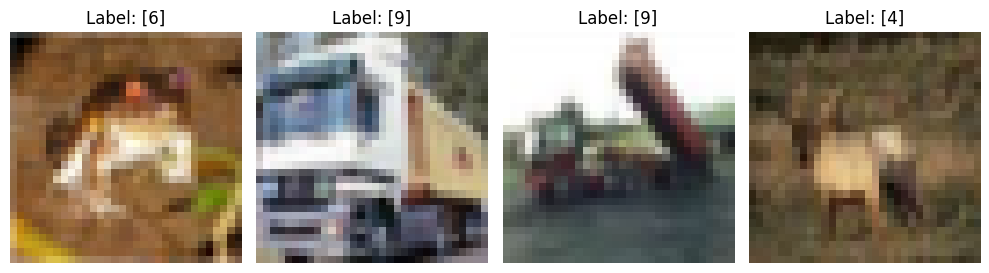

In [2]:
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt
import numpy as np

# Load the MNIST dataset
(x_train, y_train), (x_test, y_test) =  keras.datasets.cifar10.load_data()

# Print 4 images in a row
plt.figure(figsize=(10, 5))
for i in range(4):
    plt.subplot(1, 4, i+1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [3]:
num_classes = 10
input_shape = (32, 32,3)

In [4]:
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255
# Make sure images have shape (28, 28, 1)
x_train = np.expand_dims(x_train, -1)
x_test = np.expand_dims(x_test, -1)
print("x_train shape:", x_train.shape)
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")


# convert class vectors to binary class matrices
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

x_train shape: (50000, 32, 32, 3, 1)
50000 train samples
10000 test samples


In [5]:
from keras import layers

In [6]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3),activation="relu")(inputs)
x=layers.BatchNormalization()(x)
x=layers.ReLU()(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model=keras.Model(inputs,outputs)

In [7]:
model.summary()

Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d (Conv2D)             (None, 30, 30, 32)        896       
                                                                 
 batch_normalization (BatchN  (None, 30, 30, 32)       128       
 ormalization)                                                   
                                                                 
 re_lu (ReLU)                (None, 30, 30, 32)        0         
                                                                 
 flatten (Flatten)           (None, 28800)             0         
                                                                 
 dense (Dense)               (None, 10)                288010    
                                                             

In [8]:
batch_size = 128
epochs = 100

model.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.0001), metrics=["accuracy"])

history=model.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/100
352/352 [==============================] - 5s 7ms/step - loss: 1.6513 - accuracy: 0.4226 - val_loss: 1.8227 - val_accuracy: 0.4274
Epoch 2/100
352/352 [==============================] - 2s 6ms/step - loss: 1.2680 - accuracy: 0.5628 - val_loss: 1.3478 - val_accuracy: 0.5320
Epoch 3/100
352/352 [==============================] - 2s 6ms/step - loss: 1.1138 - accuracy: 0.6192 - val_loss: 1.2420 - val_accuracy: 0.5722
Epoch 4/100
352/352 [==============================] - 2s 6ms/step - loss: 1.0168 - accuracy: 0.6535 - val_loss: 1.2192 - val_accuracy: 0.5918
Epoch 5/100
352/352 [==============================] - 2s 6ms/step - loss: 0.9389 - accuracy: 0.6819 - val_loss: 1.1907 - val_accuracy: 0.5920
Epoch 6/100
352/352 [==============================] - 2s 6ms/step - loss: 0.8763 - accuracy: 0.7078 - val_loss: 1.1704 - val_accuracy: 0.6004
Epoch 7/100
352/352 [==============================] - 2s 6ms/step - loss: 0.8208 - accuracy: 0.7284 - val_loss: 1.1521 - val_accuracy: 0.6142

Epoch 58/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0561 - accuracy: 0.9970 - val_loss: 2.1282 - val_accuracy: 0.5990
Epoch 59/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0525 - accuracy: 0.9977 - val_loss: 2.1914 - val_accuracy: 0.6010
Epoch 60/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0536 - accuracy: 0.9965 - val_loss: 2.2393 - val_accuracy: 0.5912
Epoch 61/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0497 - accuracy: 0.9977 - val_loss: 2.2572 - val_accuracy: 0.5944
Epoch 62/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0438 - accuracy: 0.9983 - val_loss: 2.2610 - val_accuracy: 0.5906
Epoch 63/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0406 - accuracy: 0.9987 - val_loss: 2.2842 - val_accuracy: 0.5960
Epoch 64/100
352/352 [==============================] - 2s 6ms/step - loss: 0.0379 - accuracy: 0.9990 - val_loss: 2.3153 - val_accuracy:

In [9]:
class Weibull(keras.layers.Layer):
    def __init__(self, shape, scale, **kwargs):
        super().__init__(**kwargs)
        self.shape = shape
        self.scale = scale

    def call(self, inputs):
        inputs = tf.cast(inputs, tf.float32)
        
        # Avoid division by zero or negative scale
        z = tf.math.maximum(inputs / self.scale, 0.0)

        # Weibull CDF: 1 - exp(-(z)^shape)
        weibull_cdf = 1.0 - tf.exp(-tf.pow(z, self.shape))

        # Optional: hard-zero for negative inputs (domain of Weibull CDF is x ≥ 0)
        output = tf.where(inputs < 0, 0.0, weibull_cdf)

        return output

    def get_config(self):
        config = super().get_config()
        config.update({
            "shape": self.shape,
            "scale": self.scale,
        })
        return config


In [10]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=Weibull(shape=1,scale=5)(x)#2,5
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_ray=keras.Model(inputs,outputs)

In [11]:
model_ray.summary()

Model: "model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 32, 32, 3)]       0         
                                                                 
 conv2d_1 (Conv2D)           (None, 30, 30, 32)        896       
                                                                 
 batch_normalization_1 (Batc  (None, 30, 30, 32)       128       
 hNormalization)                                                 
                                                                 
 weibull (Weibull)           (None, 30, 30, 32)        0         
                                                                 
 flatten_1 (Flatten)         (None, 28800)             0         
                                                                 
 dense_1 (Dense)             (None, 10)                288010    
                                                           

In [12]:
model_ray.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.0001), metrics=["accuracy"])

history_ray=model_ray.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/100
352/352 [==============================] - 4s 11ms/step - loss: 1.7550 - accuracy: 0.3938 - val_loss: 1.8019 - val_accuracy: 0.4354
Epoch 2/100
352/352 [==============================] - 4s 10ms/step - loss: 1.5127 - accuracy: 0.4821 - val_loss: 1.4764 - val_accuracy: 0.4962
Epoch 3/100
352/352 [==============================] - 4s 10ms/step - loss: 1.4070 - accuracy: 0.5167 - val_loss: 1.3886 - val_accuracy: 0.5218
Epoch 4/100
352/352 [==============================] - 4s 10ms/step - loss: 1.3374 - accuracy: 0.5401 - val_loss: 1.3427 - val_accuracy: 0.5336
Epoch 5/100
352/352 [==============================] - 4s 10ms/step - loss: 1.2863 - accuracy: 0.5610 - val_loss: 1.3041 - val_accuracy: 0.5446
Epoch 6/100
352/352 [==============================] - 4s 10ms/step - loss: 1.2432 - accuracy: 0.5726 - val_loss: 1.2773 - val_accuracy: 0.5590
Epoch 7/100
352/352 [==============================] - 4s 10ms/step - loss: 1.2093 - accuracy: 0.5863 - val_loss: 1.2840 - val_accuracy:

352/352 [==============================] - 4s 10ms/step - loss: 0.6706 - accuracy: 0.7864 - val_loss: 1.0862 - val_accuracy: 0.6290
Epoch 58/100
352/352 [==============================] - 4s 10ms/step - loss: 0.6656 - accuracy: 0.7892 - val_loss: 1.0846 - val_accuracy: 0.6306
Epoch 59/100
352/352 [==============================] - 4s 10ms/step - loss: 0.6590 - accuracy: 0.7921 - val_loss: 1.0780 - val_accuracy: 0.6306
Epoch 60/100
352/352 [==============================] - 4s 10ms/step - loss: 0.6534 - accuracy: 0.7945 - val_loss: 1.1110 - val_accuracy: 0.6238
Epoch 61/100
352/352 [==============================] - 4s 10ms/step - loss: 0.6490 - accuracy: 0.7967 - val_loss: 1.0829 - val_accuracy: 0.6312
Epoch 62/100
352/352 [==============================] - 4s 10ms/step - loss: 0.6408 - accuracy: 0.7983 - val_loss: 1.0930 - val_accuracy: 0.6326
Epoch 63/100
352/352 [==============================] - 4s 10ms/step - loss: 0.6357 - accuracy: 0.8013 - val_loss: 1.1217 - val_accuracy: 0.620

the value of breast cancer

| Metric   | Weibull CDF Activation | ReLU                |
| -------- | ---------------------- | ------------------- |
| RMSE     | 0.0337                 | 0.03                |
| MAE      | 0.0231                 | 0.03                |
| MAPE     | 14.22%                 | 15.73%              |

In [13]:
inputs=keras.Input(shape=(input_shape))
x=layers.Conv2D(32,kernel_size=(3,3))(inputs)
x=layers.BatchNormalization()(x)
x=tf.keras.activations.gelu(x)
x=layers.Flatten()(x)
outputs=layers.Dense(num_classes, activation="softmax")(x)
model_gelu=keras.Model(inputs,outputs)

In [14]:
model_gelu.compile(loss="categorical_crossentropy", optimizer= keras.optimizers.Adam(learning_rate=0.0001), metrics=["accuracy"])

history_gelu=model_gelu.fit(x_train, y_train, batch_size=batch_size, epochs=epochs, validation_split=0.1)

Epoch 1/100
352/352 [==============================] - 4s 10ms/step - loss: 1.6621 - accuracy: 0.4189 - val_loss: 1.8250 - val_accuracy: 0.3888
Epoch 2/100
352/352 [==============================] - 3s 10ms/step - loss: 1.3613 - accuracy: 0.5271 - val_loss: 1.3685 - val_accuracy: 0.5226
Epoch 3/100
352/352 [==============================] - 3s 10ms/step - loss: 1.2343 - accuracy: 0.5770 - val_loss: 1.3256 - val_accuracy: 0.5424
Epoch 4/100
352/352 [==============================] - 3s 10ms/step - loss: 1.1492 - accuracy: 0.6066 - val_loss: 1.2479 - val_accuracy: 0.5644
Epoch 5/100
352/352 [==============================] - 3s 10ms/step - loss: 1.0841 - accuracy: 0.6321 - val_loss: 1.3120 - val_accuracy: 0.5490
Epoch 6/100
352/352 [==============================] - 3s 10ms/step - loss: 1.0275 - accuracy: 0.6505 - val_loss: 1.2200 - val_accuracy: 0.5724
Epoch 7/100
352/352 [==============================] - 4s 10ms/step - loss: 0.9810 - accuracy: 0.6676 - val_loss: 1.1866 - val_accuracy:

352/352 [==============================] - 3s 10ms/step - loss: 0.2051 - accuracy: 0.9587 - val_loss: 1.7161 - val_accuracy: 0.5820
Epoch 58/100
352/352 [==============================] - 3s 10ms/step - loss: 0.1999 - accuracy: 0.9600 - val_loss: 1.6883 - val_accuracy: 0.5876
Epoch 59/100
352/352 [==============================] - 3s 10ms/step - loss: 0.1931 - accuracy: 0.9628 - val_loss: 1.7420 - val_accuracy: 0.5822
Epoch 60/100
352/352 [==============================] - 4s 10ms/step - loss: 0.1852 - accuracy: 0.9654 - val_loss: 1.7972 - val_accuracy: 0.5742
Epoch 61/100
352/352 [==============================] - 3s 10ms/step - loss: 0.1813 - accuracy: 0.9671 - val_loss: 1.7604 - val_accuracy: 0.5836
Epoch 62/100
352/352 [==============================] - 3s 10ms/step - loss: 0.1751 - accuracy: 0.9682 - val_loss: 1.7668 - val_accuracy: 0.5816
Epoch 63/100
352/352 [==============================] - 3s 10ms/step - loss: 0.1687 - accuracy: 0.9703 - val_loss: 1.8595 - val_accuracy: 0.574

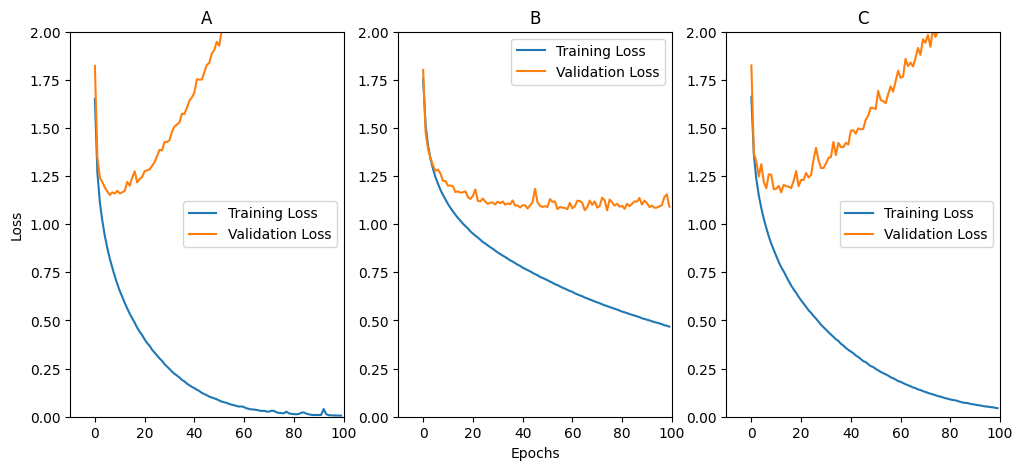

<Figure size 640x480 with 0 Axes>

In [20]:
def plot_loss_comparison(relu_history, custom_history1,custom_history2 ):
    plt.figure(figsize=(12, 5))
    
    # Set consistent axis limits
    y_min = 0
    y_max = 2
    x_max = max(len(relu_history.history['loss']), 
               len(custom_history1.history['loss']),
               len(custom_history2.history['loss']))
    
    # Plot ReLU results
    plt.subplot(1, 3, 1)
    plt.plot(relu_history.history['loss'], label='Training Loss')
    plt.plot(relu_history.history['val_loss'], label='Validation Loss')
    plt.title('A')
    plt.ylabel('Loss')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    
    # Plot Custom activation results
    plt.subplot(1, 3, 2)
    plt.plot(custom_history1.history['loss'], label='Training Loss')
    plt.plot(custom_history1.history['val_loss'], label='Validation Loss')
    plt.title('B')
    plt.xlabel('Epochs')
    plt.ylim(y_min, y_max)
    plt.xlim( -10, x_max)
    plt.legend()
    
    plt.subplot(1, 3, 3)
    plt.plot(custom_history2.history['loss'], label='Training Loss')
    plt.plot(custom_history2.history['val_loss'], label='Validation Loss')
    plt.title('C')
    plt.ylim(y_min, y_max)
    plt.xlim(-10, x_max)
    plt.legend()
    plt.show()

    plt.tight_layout()
    plt.show()

# Usage
plot_loss_comparison(history,history_ray,history_gelu)

In [16]:
score_relu = model.evaluate(x_test, y_test, verbose=0)
score_weilu = model_ray.evaluate(x_test, y_test, verbose=0)
score_gelu = model_gelu.evaluate(x_test, y_test, verbose=0)


In [21]:
print("RELU:", score_relu)
print("WeiLU:", score_weilu)
print("GELU:", score_gelu)

RELU: [3.2239327430725098, 0.5633999705314636]
WeiLU: [1.1204969882965088, 0.6240000128746033]
GELU: [2.4599854946136475, 0.5626999735832214]
